# Notebook 1: CKD Classification using Logistic Regression

**Target:** `class` (`notckd` = 0, `ckd` = 1)


## 1. Import libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [13]:
DATA_PATH = "ckd-dataset-v2-new.csv"
df = pd.read_csv(DATA_PATH)

print("Original dataset shape:", df.shape)
df.columns = df.columns.str.strip()

display(df.head())
df.info()

Original dataset shape: (200, 29)


,bp (Diastolic),bp limit,sg,al,class,rbc,su,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,grf,stage,affected,age
0,0,0,1.019 - 1.021,01-Jan,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
1,0,0,1.009 - 1.011,< 0,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
2,0,0,1.009 - 1.011,≥ 4,ckd,1,< 0,1,0,1,...,0,0,0,1,0,0,127.281 - 152.446,s1,1,< 12
3,1,1,1.009 - 1.011,03-Mar,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,127.281 - 152.446,s1,1,< 12
4,0,0,1.015 - 1.017,< 0,ckd,0,< 0,0,0,0,...,0,1,0,1,1,0,127.281 - 152.446,s1,1,Dec-20


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   bp (Diastolic)  200 non-null    int64 
 1   bp limit        200 non-null    int64 
 2   sg              200 non-null    object
 3   al              200 non-null    object
 4   class           200 non-null    object
 5   rbc             200 non-null    int64 
 6   su              200 non-null    object
 7   pc              200 non-null    int64 
 8   pcc             200 non-null    int64 
 9   ba              200 non-null    int64 
 10  bgr             200 non-null    object
 11  bu              200 non-null    object
 12  sod             200 non-null    object
 13  sc              200 non-null    object
 14  pot             200 non-null    object
 15  hemo            200 non-null    object
 16  pcv             200 non-null    object
 17  rbcc            200 non-null    object
 18  wbcc      

## 3. Clean the data

In [3]:
# Normalize target labels and remove metadata/invalid rows.
if "class" not in df.columns:
    raise ValueError("The dataset must contain a 'class' target column.")

df["class"] = df["class"].astype("string").str.strip().str.lower()
df = df[df["class"].isin(["ckd", "notckd"])].copy()

# Normalize common missing-value markers before removing duplicates.
df = df.replace(
    r"^\\s*(\\?|NA|N/A|na|n/a)\\s*$",
    np.nan,
    regex=True
)

# Strip whitespace from string/object values.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["class"].value_counts())
print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))

Cleaned dataset shape: (200, 29)

Target distribution:
class
ckd       128
notckd     72
Name: count, dtype: int64

Missing values per column:


,Missing values
bp (Diastolic),0
hemo,0
affected,0
stage,0
grf,0
ane,0
pe,0
appet,0
cad,0
dm,0


## 4. Explore the target variable

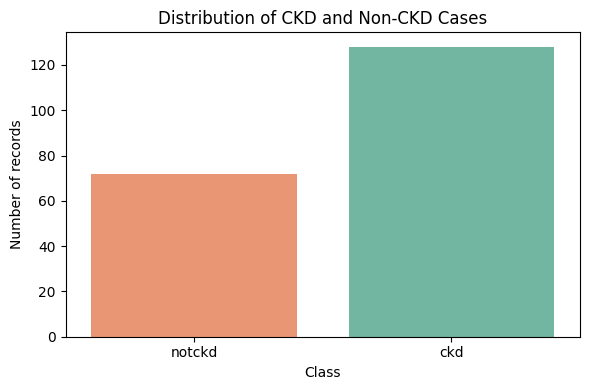

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x="class",
    order=["notckd", "ckd"],
    hue="class",
    palette="Set2",
    legend=False
)
plt.title("Distribution of CKD and Non-CKD Cases")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 5. Prepare features and target

In [5]:
# 'affected' may directly duplicate the diagnosis and 'stage' may encode
# disease severity. Exclude them to avoid potential target leakage.
excluded_columns = ["class", "affected", "stage"]

X = df.drop(columns=excluded_columns, errors="ignore").copy()
y = df["class"].map({"notckd": 0, "ckd": 1})

if y.isna().any():
    raise ValueError("Unexpected target values remain after cleaning.")

# Convert common missing markers to NaN and strip text values.
X = X.replace(
    r"^\\s*(\\?|NA|N/A|na|n/a)\\s*$",
    np.nan,
    regex=True
)
for col in X.select_dtypes(include=["object", "string"]).columns:
    X[col] = X[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Number of records:", len(X))
print("Number of input features:", X.shape[1])
print("\nTarget counts (0 = Non-CKD, 1 = CKD):")
print(y.value_counts().sort_index())

Number of records: 200
Number of input features: 26

Target counts (0 = Non-CKD, 1 = CKD):
class
0     72
1    128
Name: count, dtype: int64


## 6. Split data and save shared files

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# These files allow Notebook 2 to use exactly the same train/test records.
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_frame(name="class").to_csv("y_train.csv", index=False)
y_test.to_frame(name="class").to_csv("y_test.csv", index=False)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Shared train/test CSV files saved.")

Training records: 160
Testing records: 40
Shared train/test CSV files saved.


## 7. Preprocess features

In [7]:
# This baseline treats all predictors as categorical because this dataset
# contains categorical labels and grouped/range-valued measurements.
categorical_features = X_train.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ],
    remainder="drop"
)

## 8. Train Logistic Regression

In [8]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")

Logistic Regression training completed.


## 9. Evaluate the model

In [9]:
results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}])

display(results.round(4))
results.to_csv("logistic_results.csv", index=False)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-CKD", "CKD"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0



Classification Report:
              precision    recall  f1-score   support

     Non-CKD       1.00      1.00      1.00        14
         CKD       1.00      1.00      1.00        26

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



## 10. Confusion matrix

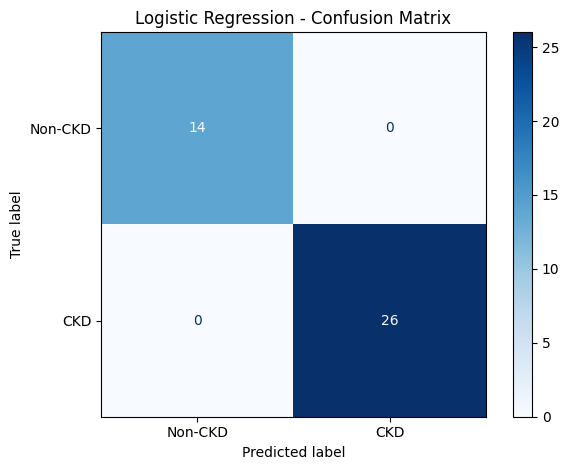

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-CKD", "CKD"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("logistic_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. ROC curve

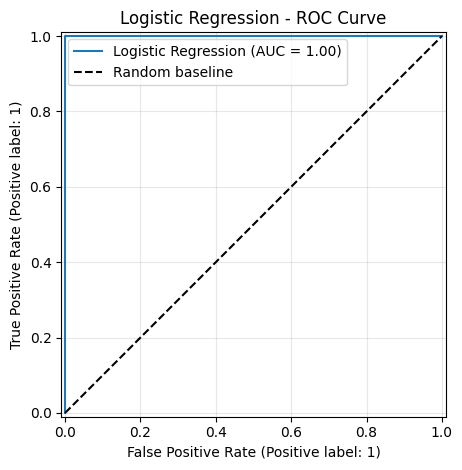

In [11]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression"
)
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.title("Logistic Regression - ROC Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("logistic_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()